# Extensive IQP quantum-kernel validation

This notebook validates every QASP kernel class and fidelity mode with
IQP-based circuits:

- `FidelityKernel`: global and user-localized projector modes, circuit
  drawings, train/test Gram matrices, differentiation, spectral diagnostics,
  and precomputed-kernel SVMs.
- `ProjectedKernel`: circuit drawing, projected quantum features, PSD and
  differentiation checks, and an SVM.
- `QFKernel`: an IQP Born circuit, Fisher-score Gram matrices, diagnostics,
  and a bit-string classification SVM.
- `KernelTargetAlignment`: optimization of a trainable IQP fidelity kernel.

The examples deliberately use small two- and three-qubit systems so the
entire notebook is practical on `default.qubit`. Assertions make failures
explicit instead of relying only on plots.


## 1. Imports and reproducibility

Install QASP in development mode before running the notebook:

```bash
python -m pip install -e ".[dev]"
```


In [1]:
from itertools import product
from pathlib import Path
import sys

# Allow execution from either the repository root or the examples folder.
repo_root = Path.cwd().resolve()
if not (repo_root / "qasp").is_dir() and (repo_root.parent / "qasp").is_dir():
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import torch
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC

from qasp import IQPAnsatz
from qasp.qkernels import (
    FidelityKernel,
    KernelTargetAlignment,
    ProjectedKernel,
    QFKernel,
    create_kernel,
    draw_kernel,
    parse_fidelity_projectors,
    target_alignment,
)

SEED = 17
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Python:", sys.version.split()[0])
print("PennyLane:", qml.__version__)
print("PyTorch:", torch.__version__)


Python: 3.10.17
PennyLane: 0.42.2
PyTorch: 2.7.0


## 2. Reusable diagnostics


In [2]:
def gram_diagnostics(
    gram,
    name,
    *,
    square=True,
    unit_diagonal=True,
    psd_expected=True,
    tolerance=1e-6,
):
    # Validate and summarize a NumPy or Torch Gram matrix.
    matrix = np.asarray(
        gram.detach().cpu().numpy() if isinstance(gram, torch.Tensor) else gram,
        dtype=float,
    )
    assert matrix.ndim == 2, f"{name}: expected a matrix, got {matrix.shape}"
    assert np.isfinite(matrix).all(), f"{name}: non-finite values found"

    result = {"kernel": name, "shape": str(matrix.shape)}
    if square:
        assert matrix.shape[0] == matrix.shape[1], f"{name}: matrix is not square"
        symmetry_error = float(np.max(np.abs(matrix - matrix.T)))
        eigenvalues = np.linalg.eigvalsh(0.5 * (matrix + matrix.T))
        min_eigenvalue = float(eigenvalues.min())
        result.update(
            symmetry_error=symmetry_error,
            min_eigenvalue=min_eigenvalue,
            psd=min_eigenvalue >= -tolerance,
        )
        assert symmetry_error <= tolerance, f"{name}: Gram matrix is not symmetric"
        if unit_diagonal:
            assert np.allclose(np.diag(matrix), 1.0, atol=tolerance), (
                f"{name}: diagonal is not one"
            )
        if psd_expected:
            assert min_eigenvalue >= -tolerance, f"{name}: Gram matrix is not PSD"
    return result


def plot_gram(gram, title, ax=None):
    matrix = np.asarray(gram, dtype=float)
    if ax is None:
        _, ax = plt.subplots(figsize=(4.5, 4))
    image = ax.imshow(matrix, cmap="viridis", aspect="auto")
    ax.set_title(title)
    ax.set_xlabel("column sample")
    ax.set_ylabel("row sample")
    plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    return ax


def svm_from_quantum_kernel(kernel, X_train, y_train, X_test, y_test):
    # Fit an SVM using QASP train and test-vs-train Gram matrices.
    train_gram = np.asarray(kernel.gram(X_train), dtype=float)
    test_gram = np.asarray(kernel.gram(X_test, X_train), dtype=float)
    assert train_gram.shape == (len(X_train), len(X_train))
    assert test_gram.shape == (len(X_test), len(X_train))

    model = SVC(kernel="precomputed", C=1.0)
    model.fit(train_gram, y_train)
    predictions = model.predict(test_gram)
    return {
        "model": model,
        "train_gram": train_gram,
        "test_gram": test_gram,
        "predictions": predictions,
        "accuracy": accuracy_score(y_test, predictions),
    }


def assert_finite_gradients(kernel):
    parameters = kernel.parameters()
    assert parameters, "Expected a trainable kernel"
    assert all(parameter.grad is not None for parameter in parameters)
    assert all(torch.isfinite(parameter.grad).all() for parameter in parameters)


def all_qubit_zero_projector(n_qubits):
    # One zero-state projector spanning every data qubit.
    return f"P {' '.join(map(str, range(n_qubits)))}"


## 3. Continuous classification data

The global-fidelity, localized-fidelity, and projected kernels operate on continuous
features. We scale a noisy two-moons dataset into $[0, \pi]$ for angle
encoding and use a fixed stratified split.


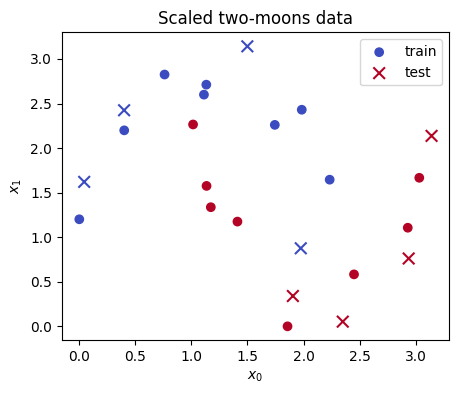

train: (16, 2) test: (8, 2)


In [3]:
N_QUBITS = 2
X, y = make_moons(n_samples=24, noise=0.12, random_state=SEED)
X = MinMaxScaler(feature_range=(0.0, np.pi)).fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=8,
    random_state=SEED,
    stratify=y,
)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", label="train")
ax.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test,
    cmap="coolwarm",
    marker="x",
    s=70,
    label="test",
)
ax.set(title="Scaled two-moons data", xlabel="$x_0$", ylabel="$x_1$")
ax.legend()
plt.show()

print("train:", X_train.shape, "test:", X_test.shape)


## 4. Shared IQP configuration


In [5]:
def iqp_kernel_config(kernel_type, *, init="small_normal", **overrides):
    config = {
        "kernel_type": kernel_type,
        "feature_map": "AngleEmbedding",
        "feature_map_config": {
            "rotations": "Y",
            "imprimitive_pattern": "ring",
        },
        "ansatz": "IQPAnsatz",
        "ansatz_config": {
            "n_layers": 2,
            "imprimitive_pattern": "ring",
            "reuploading": True,
        },
        "init": init,
        "device": "default.qubit",
        "diff_method": "best",
    }
    config.update(overrides)
    return config


torch.manual_seed(SEED)
fidelity_kernel = create_kernel(iqp_kernel_config("fidelity"), N_QUBITS)

torch.manual_seed(SEED)
local_subset_kernel = create_kernel(
    iqp_kernel_config(
        "fidelity",
        projectors=["P 0", "P 1"],
    ),
    N_QUBITS,
)

torch.manual_seed(SEED)
projected_kernel = create_kernel(
    iqp_kernel_config(
        "projected",
        observables=["X 0", "Y 0", "Z 0", "X 1", "Y 1", "Z 1"],
        gamma=0.5,
    ),
    N_QUBITS,
)

assert isinstance(fidelity_kernel, FidelityKernel)
assert isinstance(local_subset_kernel, FidelityKernel)
assert isinstance(projected_kernel, ProjectedKernel)

print("Fidelity parameters:", [tuple(p.shape) for p in fidelity_kernel.parameters()])
print("Local parameters:", [tuple(p.shape) for p in local_subset_kernel.parameters()])
print("Projected parameters:", [tuple(p.shape) for p in projected_kernel.parameters()])


Fidelity parameters: [(8,)]
Local parameters: [(8,)]
Projected parameters: [(8,)]


## 5. IQP global-fidelity kernel


Matplotlib is building the font cache; this may take a moment.


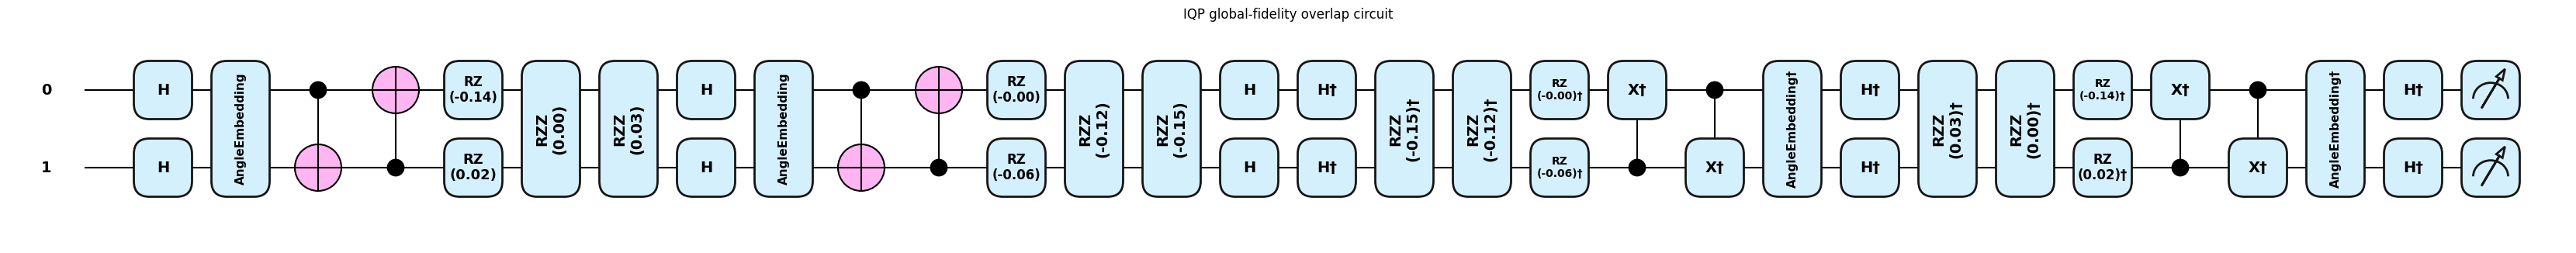

In [6]:
fig, ax = draw_kernel(
    fidelity_kernel,
    x=X_train[0],
    y=X_train[1],
    decimals=2,
)
fig.suptitle("IQP global-fidelity overlap circuit", y=1.02)
plt.show()


,kernel,shape,symmetry_error,min_eigenvalue,psd
0,IQP fidelity,"(16, 16)",0.0,2.776955e-08,True


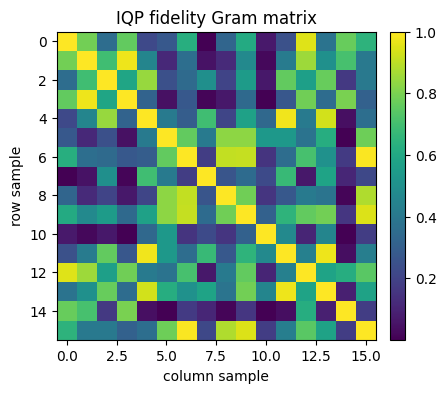

In [7]:
K_fidelity = fidelity_kernel.gram(X_train)
fidelity_diagnostics = gram_diagnostics(
    K_fidelity,
    "IQP fidelity",
    psd_expected=True,
)
display(pd.DataFrame([fidelity_diagnostics]))
plot_gram(K_fidelity, "IQP fidelity Gram matrix")
plt.show()


In [8]:
fidelity_kernel.qlayer.zero_grad()
differentiable_gram = fidelity_kernel.gram(X_train[:5], return_tensor=True)
differentiable_gram.sum().backward()
assert differentiable_gram.requires_grad
assert_finite_gradients(fidelity_kernel)
print("Fidelity Gram is differentiable; gradient checks passed.")


Fidelity Gram is differentiable; gradient checks passed.


In [9]:
fidelity_svm = svm_from_quantum_kernel(
    fidelity_kernel, X_train, y_train, X_test, y_test
)
print("Fidelity SVM accuracy:", fidelity_svm["accuracy"])
print("Confusion matrix:\n", confusion_matrix(y_test, fidelity_svm["predictions"]))


Fidelity SVM accuracy: 0.75
Confusion matrix:
 [[3 1]
 [1 3]]


## 6. IQP localized `FidelityKernel`

For a projected subset $s_\ell$, QASP measures

$$P_{s_\ell}=|0\rangle\langle0|^{s_\ell}\otimes I_{\bar{s}_\ell}$$

on the overlap state and averages the resulting probabilities. Labels such
as `"P 0 1"` and `"P 0 2"` select the projected qubits. A single projector
spanning every qubit must reproduce the global-fidelity kernel. Proper
The same `FidelityKernel` class implements both modes: omitting `projectors`
selects the global all-qubit projector. Proper subsets provide the requested
localized similarity, but are not guaranteed
to yield a PSD Gram matrix for arbitrary encoding circuits.


In [10]:
full_projector = all_qubit_zero_projector(N_QUBITS)

# Zero initialization guarantees identical IQP parameters in both objects.
exact_fidelity = create_kernel(
    iqp_kernel_config("fidelity", init="zeros"), N_QUBITS
)
explicit_global = create_kernel(
    iqp_kernel_config(
        "fidelity",
        init="zeros",
        projectors=[full_projector],
    ),
    N_QUBITS,
)

K_exact_fidelity = exact_fidelity.gram(X_train)
K_explicit_global = explicit_global.gram(X_train)
reconstruction_error = np.max(np.abs(K_exact_fidelity - K_explicit_global))
assert np.allclose(K_exact_fidelity, K_explicit_global, atol=1e-6)

print("All-qubit projector:", full_projector)
print("Projector/global reconstruction error:", f"{reconstruction_error:.3e}")

# On two qubits ["P 0", "P 1"] is exactly
# 1/2 * (|0><0| tensor I + I tensor |0><0|) on the overlap state.
local_terms = local_subset_kernel._overlap_out(
    X_train[0], X_train[1]
).detach().numpy()
local_value = local_subset_kernel.kernel(X_train[0], X_train[1])
assert local_subset_kernel.projector_wires == [[0], [1]]
assert np.isclose(local_value, 0.5 * (local_terms[0] + local_terms[1]))
print("Two-qubit local projector terms:", local_terms)
print("Their arithmetic mean:", local_value)

# Exercise the exact three-qubit syntax supported by FidelityKernel.
three_qubit_labels = ["P 0 1", "P 0 2", " P 0 1 2"]
parsed_projectors = parse_fidelity_projectors(three_qubit_labels, n_qubits=3)
X_three_qubits = np.column_stack(
    [X_train[:6], 0.5 * (X_train[:6, 0] + X_train[:6, 1])]
)
three_qubit_local = create_kernel(
    iqp_kernel_config(
        "fidelity",
        init="zeros",
        projectors=three_qubit_labels,
    ),
    n_qubits=3,
)
K_three_qubit_local = three_qubit_local.gram(X_three_qubits)
three_qubit_diagnostics = gram_diagnostics(
    K_three_qubit_local,
    "Three-qubit local projectors",
    psd_expected=False,
)
assert len(parsed_projectors) == 3
assert three_qubit_local.projector_wires == [[0, 1], [0, 2], [0, 1, 2]]
display(pd.DataFrame([three_qubit_diagnostics]))


All-qubit projector: P 0 1
Projector/global reconstruction error: 0.000e+00
Two-qubit local projector terms: [[0.84262425]
 [0.86429274]]
Their arithmetic mean: 0.8534585237503052


,kernel,shape,symmetry_error,min_eigenvalue,psd
0,Three-qubit local projectors,"(6, 6)",0.0,0.069428,True


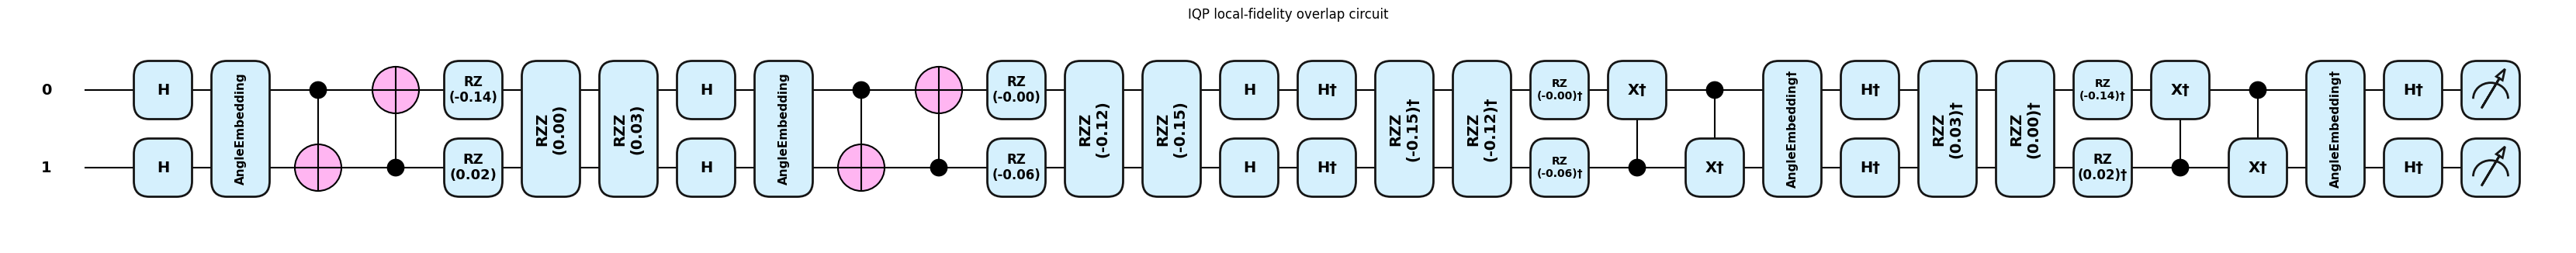

In [11]:
fig, ax = draw_kernel(
    local_subset_kernel,
    x=X_train[0],
    y=X_train[1],
    decimals=2,
)
fig.suptitle("IQP local-fidelity overlap circuit", y=1.02)
plt.show()


,kernel,shape,symmetry_error,min_eigenvalue,psd
0,IQP local fidelity,"(16, 16)",0.0,-0.255117,False


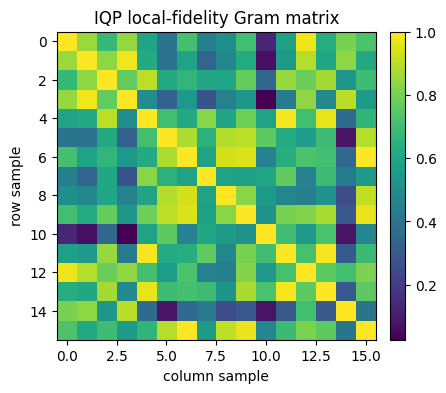

Local-fidelity SVM accuracy: 0.875
Confusion matrix:
 [[3 1]
 [0 4]]


In [12]:
K_local = local_subset_kernel.gram(X_train)
local_diagnostics = gram_diagnostics(
    K_local,
    "IQP local fidelity",
    psd_expected=False,
)
local_subset_kernel.qlayer.zero_grad()
local_subset_kernel.gram(X_train[:5], return_tensor=True).sum().backward()
assert_finite_gradients(local_subset_kernel)

local_svm = svm_from_quantum_kernel(
    local_subset_kernel, X_train, y_train, X_test, y_test
)
display(pd.DataFrame([local_diagnostics]))
plot_gram(K_local, "IQP local-fidelity Gram matrix")
plt.show()
print("Local-fidelity SVM accuracy:", local_svm["accuracy"])
print("Confusion matrix:\n", confusion_matrix(y_test, local_svm["predictions"]))


## 7. IQP projected kernel


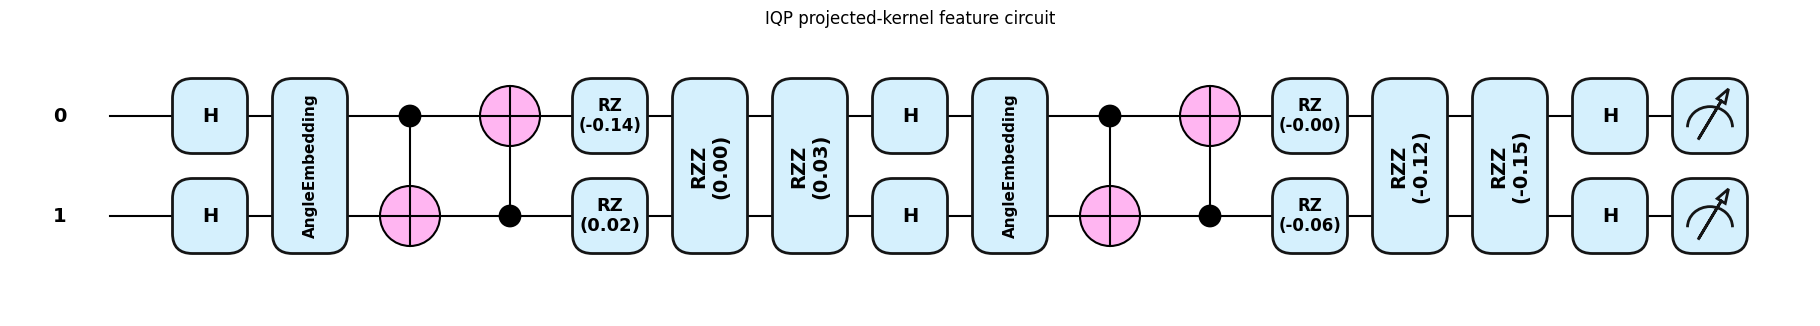

In [13]:
fig, ax = draw_kernel(projected_kernel, x=X_train[0], decimals=2)
fig.suptitle("IQP projected-kernel feature circuit", y=1.02)
plt.show()


In [14]:
projected_features = projected_kernel.features(X_train)
assert projected_features.shape == (len(X_train), 6)
assert np.isfinite(projected_features).all()

feature_frame = pd.DataFrame(
    projected_features,
    columns=projected_kernel.observable_labels,
)
display(feature_frame.head())


,X 0,Y 0,Z 0,X 1,Y 1,Z 1
0,-0.086471,0.080924,-0.786203,-0.592593,0.029587,0.529243
1,-0.738557,0.012485,-0.456227,-0.587501,-0.082833,0.633835
2,-0.835940,-0.064763,0.523895,-0.981485,-0.118919,0.001024
3,-0.606283,-0.004081,-0.550118,-0.318345,-0.106613,0.746670
4,-0.778911,-0.038581,0.269857,-0.819733,0.043351,-0.084685


,kernel,shape,symmetry_error,min_eigenvalue,psd
0,IQP projected,"(16, 16)",0.0,0.000299,True


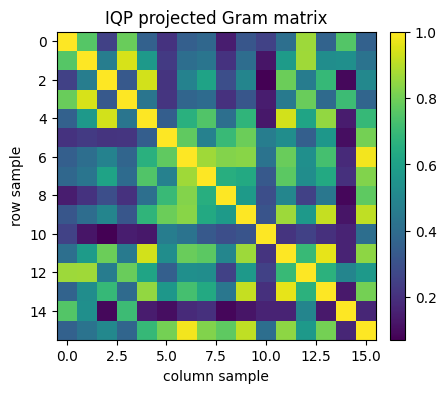

Projected-kernel SVM accuracy: 0.75
Confusion matrix:
 [[3 1]
 [1 3]]


In [15]:
K_projected = projected_kernel.gram(X_train)
projected_diagnostics = gram_diagnostics(
    K_projected,
    "IQP projected",
    psd_expected=True,
)

projected_kernel.qlayer.zero_grad()
projected_kernel.gram(X_train[:5], return_tensor=True).sum().backward()
assert_finite_gradients(projected_kernel)

projected_svm = svm_from_quantum_kernel(
    projected_kernel, X_train, y_train, X_test, y_test
)
display(pd.DataFrame([projected_diagnostics]))
plot_gram(K_projected, "IQP projected Gram matrix")
plt.show()
print("Projected-kernel SVM accuracy:", projected_svm["accuracy"])
print("Confusion matrix:\n", confusion_matrix(y_test, projected_svm["predictions"]))


## 8. Compare the three continuous-data SVMs


,kernel,accuracy,min eigenvalue
1,IQP local fidelity,0.875,-2.551166e-01
0,IQP fidelity,0.750,2.776955e-08
2,IQP projected,0.750,2.993809e-04


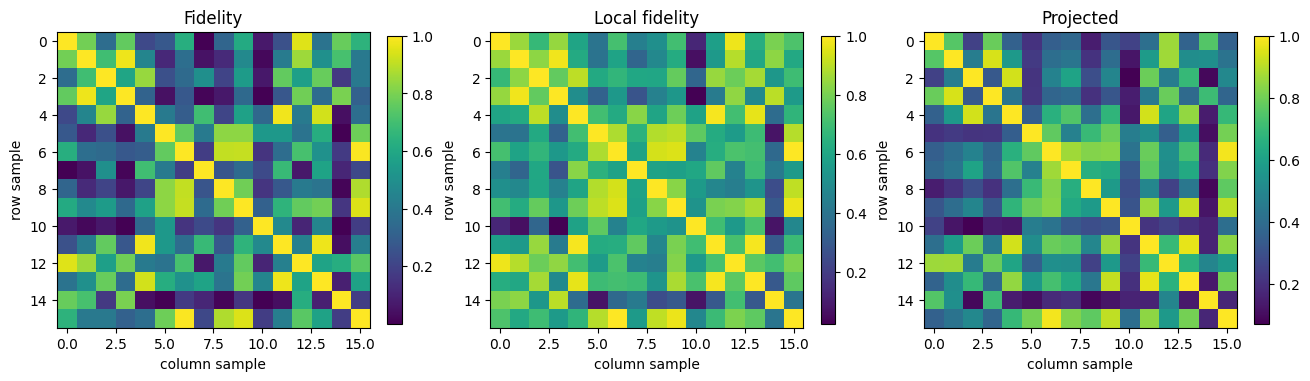

In [16]:
continuous_results = pd.DataFrame(
    [
        {
            "kernel": "IQP fidelity",
            "accuracy": fidelity_svm["accuracy"],
            "min eigenvalue": fidelity_diagnostics["min_eigenvalue"],
        },
        {
            "kernel": "IQP local fidelity",
            "accuracy": local_svm["accuracy"],
            "min eigenvalue": local_diagnostics["min_eigenvalue"],
        },
        {
            "kernel": "IQP projected",
            "accuracy": projected_svm["accuracy"],
            "min eigenvalue": projected_diagnostics["min_eigenvalue"],
        },
    ]
).sort_values("accuracy", ascending=False)
display(continuous_results)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), constrained_layout=True)
plot_gram(K_fidelity, "Fidelity", axes[0])
plot_gram(K_local, "Local fidelity", axes[1])
plot_gram(K_projected, "Projected", axes[2])
plt.show()


## 9. Train an IQP fidelity kernel with target alignment

This is a smoke test for end-to-end differentiation through every entry of
a Gram matrix. A small balanced subset keeps the optimization inexpensive.


step   1/5  alignment=0.4315
step   2/5  alignment=0.4319
step   3/5  alignment=0.4325
step   4/5  alignment=0.4335
step   5/5  alignment=0.4347


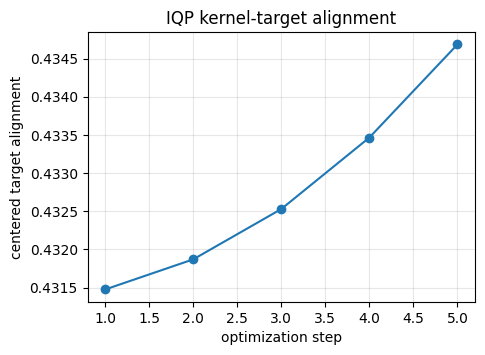

alignment before: 0.431476
alignment after:  0.436192


In [17]:
class_zero = np.flatnonzero(y_train == 0)[:4]
class_one = np.flatnonzero(y_train == 1)[:4]
alignment_indices = np.concatenate([class_zero, class_one])
X_alignment = X_train[alignment_indices]
y_alignment = y_train[alignment_indices]

torch.manual_seed(SEED + 1)
aligned_kernel = create_kernel(
    iqp_kernel_config("fidelity", init="small_normal"), N_QUBITS
)
parameters_before = [p.detach().clone() for p in aligned_kernel.parameters()]
alignment_before = target_alignment(aligned_kernel.gram(X_alignment), y_alignment)

history = KernelTargetAlignment(aligned_kernel).fit(
    X_alignment,
    y_alignment,
    steps=5,
    lr=0.02,
    seed=SEED,
    verbose=True,
)
alignment_after = target_alignment(aligned_kernel.gram(X_alignment), y_alignment)

assert len(history["alignment"]) == 5
assert np.isfinite(history["alignment"]).all()
assert any(
    not torch.allclose(old, new)
    for old, new in zip(parameters_before, aligned_kernel.parameters())
)

plt.figure(figsize=(5, 3.5))
plt.plot(np.arange(1, 6), history["alignment"], marker="o")
plt.xlabel("optimization step")
plt.ylabel("centered target alignment")
plt.title("IQP kernel-target alignment")
plt.grid(alpha=0.3)
plt.show()

print(f"alignment before: {alignment_before:.6f}")
print(f"alignment after:  {alignment_after:.6f}")


In [18]:
svm_from_quantum_kernel(
    aligned_kernel, X_train, y_train, X_test, y_test)

{'model': SVC(kernel='precomputed'),
 'train_gram': array([[1.00000012, 0.78469515, 0.36245263, 0.75512135, 0.22581808,
         0.26855478, 0.61915898, 0.00662823, 0.31605345, 0.60748655,
         0.06815192, 0.25422579, 0.95122689, 0.38830727, 0.75849521,
         0.63987297],
        [0.78469515, 0.99999988, 0.69766849, 0.97031689, 0.46039829,
         0.11130698, 0.34709963, 0.05828771, 0.10971817, 0.45954642,
         0.02597511, 0.41908911, 0.84871703, 0.50444013, 0.70758724,
         0.39260885],
        [0.36245263, 0.69766849, 0.99999994, 0.59683353, 0.8463279 ,
         0.23524073, 0.32748342, 0.50649619, 0.18801148, 0.53094518,
         0.07615431, 0.75767612, 0.55668437, 0.76153535, 0.18751267,
         0.38513002],
        [0.75512135, 0.97031689, 0.59683353, 0.99999958, 0.32190806,
         0.04526848, 0.26200086, 0.02675457, 0.05809811, 0.33250391,
         0.00190462, 0.27591681, 0.77120489, 0.35041881, 0.80507135,
         0.29598242],
        [0.22581808, 0.46039829, 

## 10. Fisher-information kernel from an IQP Born circuit

`QFKernel` works on observed bit strings rather than continuous feature
vectors. We construct a three-qubit IQP probability model, inspect its
circuit, build the Fisher-score Gram matrix, and classify bit-string parity.


In [ ]:
QF_QUBITS = 3
qf_ansatz = IQPAnsatz(
    n_qubits=QF_QUBITS,
    n_layers=2,
    imprimitive_pattern="ring",
)
# The extra device wire is available to quantum-Fisher transforms that
# use an auxiliary wire internally.
qf_device = qml.device("default.qubit", wires=QF_QUBITS + 1)

@qml.qnode(qf_device)
def iqp_born_circuit(params):
    qf_ansatz(params=params)
    return qml.probs(wires=range(QF_QUBITS))

parameter_shape = qf_ansatz.get_param_shapes()[0]
qf_params = qml.numpy.array(
    rng.uniform(-0.7, 0.7, size=parameter_shape),
    requires_grad=True,
)

probabilities = iqp_born_circuit(qf_params)
assert probabilities.shape == (2**QF_QUBITS,)
assert np.all(probabilities > 1e-10), "Choose a new seed if a probability vanishes"
assert np.isclose(np.sum(probabilities), 1.0)

fig, ax = qml.draw_mpl(iqp_born_circuit, decimals=2)(qf_params)
fig.suptitle("Three-qubit IQP Born circuit for QFKernel", y=1.02)
plt.show()


In [ ]:
bitstrings = np.array(list(product([0, 1], repeat=QF_QUBITS)), dtype=int)
parity_labels = bitstrings.sum(axis=1) % 2
train_indices = np.array([0, 1, 2, 3, 4, 5])
test_indices = np.array([6, 7])
bits_train, bits_test = bitstrings[train_indices], bitstrings[test_indices]
parity_train, parity_test = parity_labels[train_indices], parity_labels[test_indices]

fisher_kernel = QFKernel(
    iqp_born_circuit,
    qf_params,
    fisher="quantum",
    lambda_reg=1e-2,
)
K_fisher_train = np.asarray(fisher_kernel.gram(bits_train), dtype=float)
K_fisher_test = np.asarray(
    fisher_kernel.gram(bits_test, bits_train), dtype=float
)

fisher_diagnostics = gram_diagnostics(
    K_fisher_train,
    "IQP Fisher information",
    unit_diagonal=False,
    psd_expected=True,
)
fisher_svm = SVC(kernel="precomputed", C=1.0).fit(
    K_fisher_train, parity_train
)
fisher_predictions = fisher_svm.predict(K_fisher_test)
fisher_accuracy = accuracy_score(parity_test, fisher_predictions)

display(pd.DataFrame([fisher_diagnostics]))
plot_gram(K_fisher_train, "IQP Fisher-score Gram matrix")
plt.show()
print("Fisher-kernel parity accuracy:", fisher_accuracy)
print("predictions:", fisher_predictions, "targets:", parity_test)


## 11. Explicit failure-mode checks


In [ ]:
def expect_value_error(description, operation):
    try:
        operation()
    except ValueError as error:
        print(f"PASS - {description}: {error}")
    else:
        raise AssertionError(f"Expected ValueError: {description}")


expect_value_error(
    "fidelity rejects labels without the P prefix",
    lambda: create_kernel(
        iqp_kernel_config("fidelity", projectors=["Z 0"]),
        N_QUBITS,
    ),
)
expect_value_error(
    "projected kernel rejects a negative gamma",
    lambda: create_kernel(
        iqp_kernel_config("projected", gamma=-1.0),
        N_QUBITS,
    ),
)
expect_value_error(
    "kernel rejects the wrong feature dimension",
    lambda: fidelity_kernel.gram(np.ones((3, N_QUBITS + 1))),
)
expect_value_error(
    "factory rejects an unknown kernel type",
    lambda: create_kernel(iqp_kernel_config("unknown"), N_QUBITS),
)


## 12. Final validation summary


In [ ]:
final_summary = pd.DataFrame(
    [
        {"kernel": "FidelityKernel (global)", "IQP": True, "SVM accuracy": fidelity_svm["accuracy"]},
        {"kernel": "FidelityKernel (localized)", "IQP": True, "SVM accuracy": local_svm["accuracy"]},
        {"kernel": "ProjectedKernel", "IQP": True, "SVM accuracy": projected_svm["accuracy"]},
        {"kernel": "QFKernel", "IQP": True, "SVM accuracy": fisher_accuracy},
    ]
)
display(final_summary)

assert set(final_summary["kernel"]) == {
    "FidelityKernel (global)",
    "FidelityKernel (localized)",
    "ProjectedKernel",
    "QFKernel",
}
assert np.isfinite(final_summary["SVM accuracy"]).all()
print("All IQP quantum-kernel notebook checks completed successfully.")
